# 04a — Evaluación de LLM

<figure>
<a
href="https://colab.research.google.com/github/Adamychen/m10_quarto/blob/main/notebooks/bloque4/04a-evaluacion.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

> Este tema forma parte del [Bloque 4 — Gobernanza](04-gobernanza.qmd).
> Se recomienda seguir el orden de las subsecciones.

## 1. Evaluación de LLM

La evaluación de un sistema con LLM no es un trámite: es la diferencia
entre un prototipo que “parece funcionar” y un producto que cumple
objetivos de calidad medibles.

Hay tres familias principales:

1.  Métricas automáticas de referencia (reference-based): comparan
    directamente la salida del modelo contra una respuesta correcta, lo
    que se conoce comúnmente como *ground truth*. Incluyen métricas de
    coincidencia de palabras (como ROUGE o BLEU) o de similitud
    semántica (como BERTScore). Son sumamente rápidas, reproducibles y
    baratas de calcular, pero resultan superficiales al no tolerar bien
    la variabilidad del lenguaje natural.

2.  LLM-as-a-judge: como su nombre indica, empleamos un LLM como
    evaluador. Este método es muy flexible debido a todas las
    capacidades que tienen estos modelos para seguir instrucciones
    mediante prompts (esto permite una primera aproximación rápida sin
    tener que programar nada) y es razonablemente fiable, siempre y
    cuando las capacidades de dicho modelo sean suficientes para la
    tarea que se le ha encomendado.

3.  Frameworks integrados (RAGAS, DeepEval, LangSmith): son librerías y
    plataformas que orquestan y combinan los dos enfoques anteriores.
    Además de calcular métricas, gestionan múltiples *datasets* de
    prueba que permiten definir umbrales de calidad integrados en flujos
    de CI/CD (*continuous integration*/*continuous delivery*) como
    pruebas unitarias. Los frameworks integrados ofrecen paneles
    visuales para monitorizar el rendimiento, la latencia y el coste de
    sistemas completos.

Evaluar LLM es especialmente difícil porque las salidas son libres
(texto no estructurado), pueden existir múltiples respuestas correctas y
la noción de “correcto” es a menudo subjetiva (¿qué cuenta como una
buena paráfrasis?). Esto obliga a combinar señales en lugar de confiar
en una sola métrica.

> **El espejo humano: los límites de la evaluación**
>
> Si evaluar a un LLM es complejo, es porque evaluar el desempeño de un
> ser humano en tareas creativas o de comunicación también lo es. En
> múltiples áreas del conocimiento, el acuerdo entre evaluadores rara
> vez es absoluto; dos expertos en dichas áreas pueden discrepar sobre
> numerosos puntos de corrección al ser un problema multidimensional.
>
> Por ello, al evaluar LLM no buscamos una métrica perfecta, sino
> establecer un marco de consenso que minimice los riesgos (información
> falsa, lenguaje ofensivo) de utilizar y confiar en sistemas basados en
> estos modelos.

<figure id="fig-flujo-evaluacion">
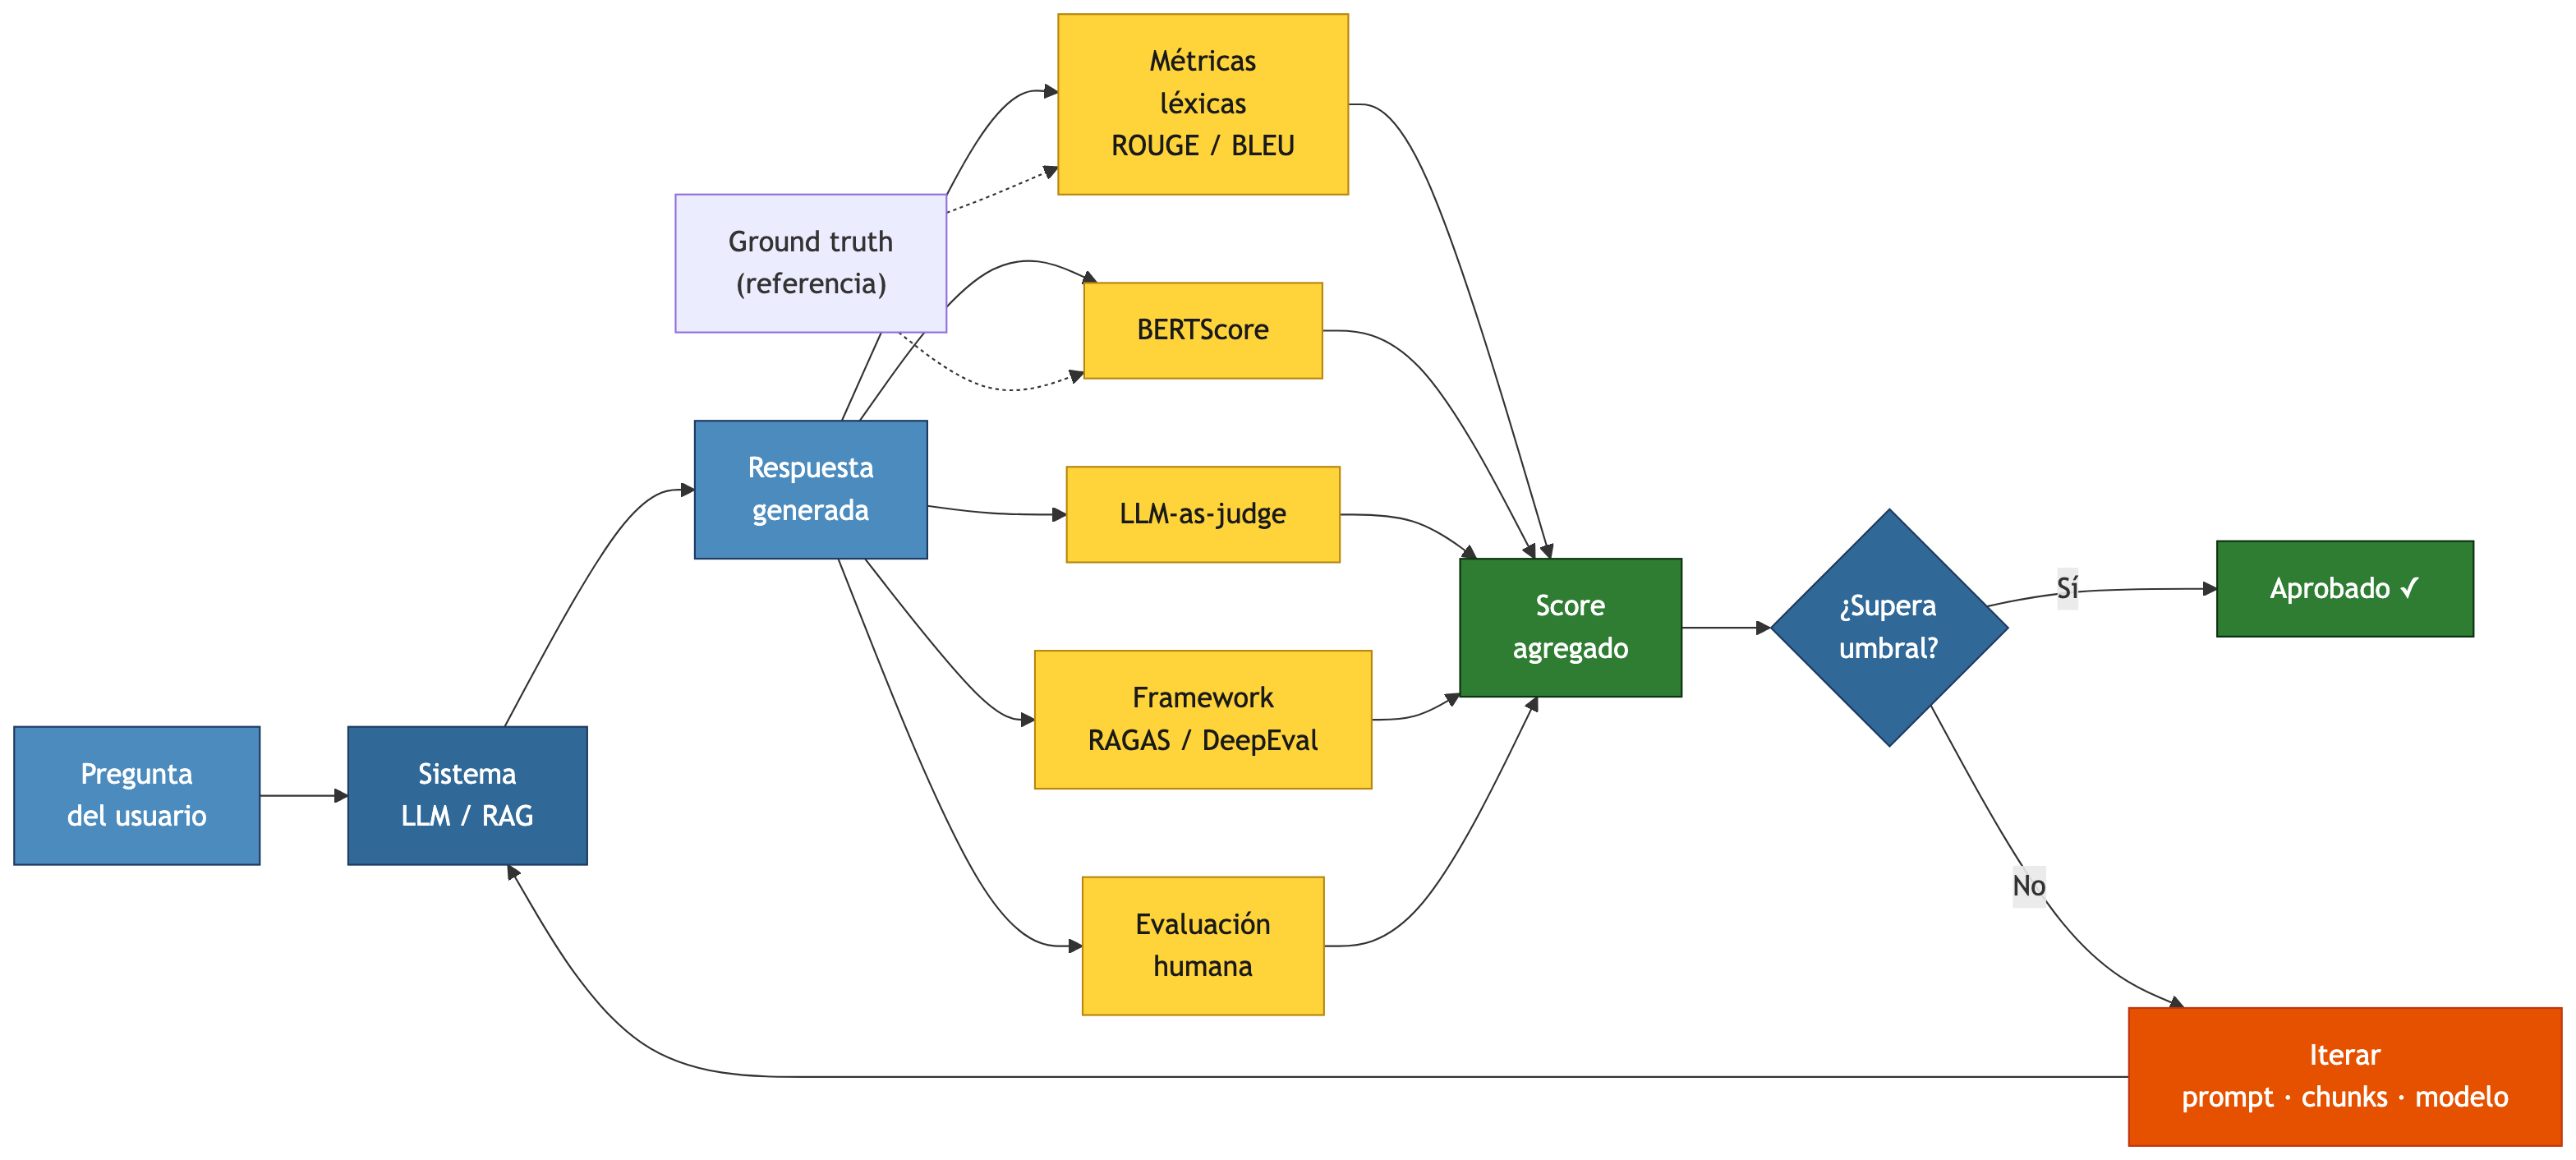
<figcaption>Figure 1</figcaption>
</figure>

Tres reglas prácticas para guiar el resto de este tema:

1.  Ninguna métrica automática sustituye al evaluador humano para
    producción crítica. Úsalas para iterar rápido en desarrollo, no para
    certificar calidad.
2.  Combina siempre varias señales. Una sola métrica es fácil de
    “engañar” (manipular). Tres señales complementarias son robustas.
3.  Versiona los datasets de evaluación. Cada cambio (prompt, modelo,
    chunk size) requiere reevaluar contra el mismo conjunto de datos, si
    quieres comparar honestamente.

### 1.1 Benchmarks públicos y leaderboards

Las secciones
<a href="#sec-metricas-auto" class="quarto-xref">Section 0.1.2</a>–<a href="#sec-frameworks" class="quarto-xref">Section 0.1.4</a>
cubren cómo evaluar un sistema (con tus datos, tus prompts, tu
pipeline). Pero antes de construir nada, conviene conocer los benchmarks
públicos que la comunidad usa para comparar modelos entre sí: son
exámenes estandarizados a los que se somete cada modelo antes de que te
lo plantees usar.

Para que la evaluación de un LLM deje de ser una apreciación subjetiva y
se convierta en ciencia reproducible, un benchmark debe formalizar el
proceso combinando estrictamente tres componentes inmutables:

1.  Un dataset de evaluación inmutable: Es el corpus de prueba
    (preguntas, contextos, problemas de código o prompts estructurados)
    que permanece idéntico para todos los modelos. Esto garantiza que
    todos los sujetos se enfrenten exactamente al mismo “examen” y bajo
    las mismas condiciones de dificultad.
2.  Una métrica cuantitativa unificada: Define la regla matemática o el
    algoritmo con el que se juzgarán las respuestas (por ejemplo,
    Accuracy para opción múltiple, F1-score para extracción de
    información, o pass@k para verificar si el código generado pasa
    tests unitarios). Al estar automatizada y estandarizada, se elimina
    el sesgo del evaluador.
3.  Un protocolo de ejecución rígido: Establece la configuración técnica
    exacta con la que se debe consultar al modelo. Esto incluye: • El
    formato del prompt: Si se usa Zero-shot (ir directo a la pregunta) o
    Few-shot (darle ejemplos previos), y si se obliga al modelo a
    razonar antes de responder (como en Chain of Thought). • Parámetros
    de generación: La temperatura (normalmente configurada en 0 para
    buscar respuestas deterministas), penalizaciones de presencia o
    frecuencia, y límites estrictos de tokens de salida.

Gracias a esa combinación fija, dos equipos independientes pueden
evaluar el mismo modelo y obtener el mismo número: el resultado es
comparable. Esto es justo lo que las métricas reference-based de
<a href="#sec-metricas-auto" class="quarto-xref">Section 0.1.2</a> no
pueden darte a nivel de modelo: tú comparas *tu salida* con *tu
referencia*, pero no sabes si tu salida es buena en términos absolutos.

#### Benchmarks clave

| Benchmark | Mide | Cuándo mirarlo |
|------------------------|------------------------|------------------------|
| **MTEB** (Massive Text Embedding Benchmark) | Calidad de embeddings (STS, retrieval, clustering, clasificación…) | Elegir modelo de embeddings |
| **MMLU** / **MMLU-Pro** | Conocimiento general multi-tarea (57 materias) | Comparar LLM generalistas |
| **GSM8K** / **MATH** | Razonamiento matemático paso a paso | Evaluar capacidad de cálculo |
| **HumanEval** / **MBPP** / **BigCodeBench** | Generación de código (pass@k) | Tareas de code-completion |
| **TruthfulQA** | Veracidad frente a respuestas plausibles falsas | Riesgo de alucinación |
| **LMSYS Chatbot Arena** | Preferencia humana (ELO entre modelos) | Calidad conversacional percibida |
| **Open LLM Leaderboard** | Agregado de varios benchmarks | Vista panorámica de modelos open-weight |
| **HELM** | Holístico (múltiples métricas y escenarios a la vez) | Auditoría integral |

Table 1: Benchmarks públicos clave para evaluar LLM

> **¿Por qué MTEB aparece primero?**
>
> Porque en este módulo ya lo usas: el [HPD 1 ejecuta
> MTEB](../bloque1/hpd1-embeddings.qmd#sec-mteb-hpd1) sobre BIOSSES y
> STS12, y el [entregable de HPD 1](../evaluables/hpd1-entregable.qmd)
> te pide justificar la elección de un modelo de embeddings con
> evidencia de recuperación (tus propias métricas y las tareas de
> *Retrieval* de MTEB), explicando por qué una nota de STS no basta.
> Esta sección te ofrece el marco conceptual que da sentido a esa
> práctica.

#### Cómo leer un leaderboard críticamente

Un número alto en un leaderboard no es una garantía de calidad para tu
caso. Existen muchos trabajos que han analizado los problemas y límites
que tiene la evaluación mediante *benchmarks*.

Entre las cuatro trampas frecuentes se encuentran:

1.  **Contamination / overfitting.** Si un modelo se entrenó (total o
    parcialmente) con el dataset del benchmark, su score es artificial.
    Los Model Cards de HuggingFace suelen advertirlo; busca la frase
    *“trained on”* o *“evaluated on”*. Para MMLU y HumanEval hay
    análisis públicos de contamination que conviene revisar antes de
    fiarte.
2.  **Saturación.** Cuando todos los modelos punteros pasan del 95 % (lo
    que ya ocurre con MMLU desde 2024), el benchmark deja de
    discriminar: ya no diferencia “muy bueno” de “excelente”. La señal
    útil está en benchmarks sucesores más duros (MMLU-Pro, GPQA) o en
    evaluaciones humanas (LMSYS Arena).
3.  **El benchmark no es tu dominio.** MMLU aprueba un examen académico
    multi-tema; HumanEval resuelve funciones cortas de Python. Ninguno
    mide “responder preguntas sobre los PDFs de tu empresa”. Para eso
    existen las métricas y frameworks de
    <a href="#sec-metricas-auto" class="quarto-xref">Section 0.1.2</a>–<a href="#sec-frameworks" class="quarto-xref">Section 0.1.4</a>:
    tu corpus, tus preguntas, tu ground truth.
4.  **Métrica ≠ utilidad.** TruthfulQA puntúa “no inventar”, pero tu
    sistema puede fallar de formas que TruthfulQA no captura
    (alucinaciones con cifras concretas, formato incorrecto, pérdida del
    contexto RAG). Usa los benchmarks para filtrar candidatos, no para
    certificar el despliegue final.

#### Conexión con el resto del módulo

Los benchmarks no aparecen solo en el Bloque 4:

- **Bloque 1** — el [Model Card de HuggingFace](../bloque1/01b-llms.qmd)
  (Hugging Face, 2025) lista el “benchmark esperado” del modelo, y el
  HPD 1 lo usa de forma práctica.
- **Bloque 3** — al hablar de QLoRA frente a LoRA (Dettmers et al.,
  2023; Hu et al., 2022), la diferencia se reporta en “\<2 % en
  benchmarks” (pérdida menor de capacidad por la cuantización).
- **Proyecto integrador** — la rúbrica del proyecto final puede pedirte
  que justifiques la elección de un modelo de embeddings o de un LLM; un
  leaderboard es la primera evidencia que citarás.

En resumen: los benchmarks son el filtro de entrada (¿qué modelos merece
la pena probar?), no el veredicto final (¿es bueno *mi* sistema?).
<a href="#sec-metricas-auto" class="quarto-xref">Section 0.1.2</a>–<a href="#sec-frameworks" class="quarto-xref">Section 0.1.4</a>
cubren la segunda pregunta.

### 1.2 Métricas automáticas (reference-based)

Las métricas automáticas comparan la salida del modelo contra una o
varias respuestas de referencia (ground truth). Son rápidas y
reproducibles —no necesitan GPU ni LLM externo— pero capturan solo
coincidencia superficial, no comprensión real.

| Métrica | Compara | Rango | Cuándo usarla |
|------------------|------------------|------------------|------------------|
| **ROUGE-L** | Subsecuencia común más larga entre candidato y referencia | \[0, 1\] | Resúmenes, respuestas largas |
| **BERTScore** | Similitud de embeddings contextualizados | \[0, 1\] | Captura paráfrasis (no solo palabras) |
| **BLEU** | n-gramas compartidos (precisión) | \[0, 1\] | Traducción, generación corta |
| **Exact Match (EM)** | Coincidencia literal tras normalizar | {0, 1} | Respuestas factuales cortas |

Table 2: Métricas automáticas reference-based más usadas

#### Intuición de ROUGE-L: la subsecuencia común

ROUGE-L mide la subsecuencia común más larga (LCS, *longest common
subsequence*) entre candidato y referencia. Una subsecuencia es una
secuencia de tokens que aparece en ambos textos en el mismo orden
relativo, pero no necesariamente contigua. Por ejemplo, dadas las dos
frases:

- *“el gato come pescado”*
- *“el perro come atún”*

la LCS es el come (2 tokens), ya que las palabras *gato/perro* y
*pescado/atún* son distintas y no computan como coincidencia.

La idea detrás de ROUGE-L es que premia que las palabras idénticas
aparezcan en el mismo orden relativo, permitiendo que haya palabras
diferentes intercaladas en medio. Sin embargo, tiene una limitación
crucial: exige coincidencia exacta de palabras. Si el candidato utiliza
sinónimos (como *felino* en lugar de *gato*) o reformula la frase con
otro vocabulario, ROUGE-L no los detectará y la puntuación bajará. Esta
limitación fue resuelta por BERTScore.

La *L* de ROUGE-L viene precisamente de *longest*: de todas las
subsecuencias comunes, elegimos la más larga. ROUGE también tiene
variantes como ROUGE-1, ROUGE-2 (n-gramas de 1 o 2 palabras) y ROUGE-W
(pondera LCS contiguas); ROUGE-L es la más popular por su equilibrio
entre sensibilidad y robustez.

In [1]:
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

referencia = "El Transformer utiliza atención multi-cabeza para modelar dependencias"
candidatos = [
    "El Transformer usa atención multi-cabeza para dependencias", # buena
    "El modelo aplica self-attention con múltiples cabezas", # paráfrasis
    "Las redes recurrentes procesan secuencias con LSTM"
]

print(f"Referencia: {referencia}\n")
for c in candidatos:
    scores = scorer.score(referencia, c)
    # Obtenemos la métrica agregada F1-Score (fmeasure)
    print(f"   ROUGE-L = {scores['rougeL'].fmeasure:.3f} -> {c}")

Referencia: El Transformer utiliza atención multi-cabeza para modelar dependencias

   ROUGE-L = 0.842 -> El Transformer usa atención multi-cabeza para dependencias
   ROUGE-L = 0.211 -> El modelo aplica self-attention con múltiples cabezas
   ROUGE-L = 0.000 -> Las redes recurrentes procesan secuencias con LSTM

Fíjate en la F-score con `beta`: si `beta = 1`, precisión y recall pesan
igual. Si `beta < 1` (p. ej. `0.5`), la precisión pesa más, lo que
penaliza respuestas largas con información extra. Para resúmenes suele
usarse `beta` mayor (favorecer recall).

#### Cuándo ROUGE miente

ROUGE mide estructura narrativa, no corrección factual. Esto produce
tres tipos de fallo típicos:

| Caso | ROUGE-L | Realidad |
|------------------------|------------------------|------------------------|
| Paráfrasis perfecta con palabras distintas | ~0.4–0.5 | La respuesta es correcta |
| Fecha incorrecta pero estructura idéntica | ~0.7 | La respuesta es incorrecta |
| Respuesta “No tengo información” cuando no hay contexto | 0.0 | La respuesta es apropiada |

Table 3: Casos típicos en los que ROUGE-L produce un score engañoso

El segundo caso es el más peligroso: una respuesta que suena plausible y
comparte la estructura de la referencia obtendrá un score alto aunque el
dato clave sea falso. Por eso ROUGE nunca debe ser la única métrica de
un sistema en producción.

#### BERTScore vs ROUGE: significado vs palabras

BERTScore reemplaza la comparación palabra-por-palabra por una
comparación de embeddings contextualizados generados por un modelo tipo
BERT. En lugar de preguntar *“¿coincide la palabra ‘atención’?”*,
pregunta *“¿el embedding contextual de ‘atención’ en esta frase es
similar al embedding de ‘self-attention’ en la frase de referencia?”*.
Esto captura paráfrasis que ROUGE pierde.

| Frase del candidato | Frase de la referencia | ROUGE-L | BERTScore |
|------------------|------------------|------------------|------------------|
| “usa atención multi-cabeza” | “usa self-attention con varias cabezas” | ~0.5 | ~0.9 |
| “aplica atención convolucional” | “usa auto-atención” | ~0.4 | ~0.7 |

Table 4: Comparativa de BERTScore frente a ROUGE-L en paráfrasis

La segunda fila muestra la limitación clave de BERTScore: si la
respuesta dice algo *plausible pero incorrecto* (atención convolucional
en lugar de auto-atención), los embeddings siguen siendo cercanos y
BERTScore da un score engañosamente alto. Por eso BERTScore complementa,
pero no sustituye, a LLM-as-judge o evaluación humana.

> **Limitación fundamental de las métricas reference-based**
>
> ROUGE/BLEU/BERTScore miden similitud con la referencia, no corrección
> factual. Una respuesta factualmente correcta pero con palabras
> distintas obtendrá score bajo; una respuesta incorrecta pero
> estructuralmente similar obtendrá score alto. Para detectar errores
> reales necesitas LLM-as-a-judge o evaluación humana.

### 1.3 LLM-as-a-judge

La técnica de LLM-as-a-judge consiste en utilizar un modelo de lenguaje
avanzado como evaluador automático. A diferencia de las métricas léxicas
o basadas en embeddings
(<a href="#sec-metricas-auto" class="quarto-xref">Section 0.1.2</a>),
que realizan comparaciones superficiales o matemáticas de vectores, el
LLM-as-a-judge analiza la calidad de la salida interpretando el
significado, la coherencia lógica y la adecuación contextual, de forma
muy cercana a como lo haría un experto humano.

#### ¿Por qué funciona este enfoque?

La fiabilidad de este paradigma se apoya en la hipótesis de alineación.
Los LLM punteros han sido entrenados mediante aprendizaje por refuerzo
con feedback humano (RLHF) y optimización de preferencias (DPO). Este
proceso no solo les capacita para seguir instrucciones, sino que les
dota de una “sensibilidad” interna hacia los criterios de calidad humana
(corrección, veracidad, tono y estructura). Múltiples estudios
demuestran que la correlación de las decisiones de un juez potente (como
GPT o Claude) con las de evaluadores humanos (comités de expertos) suele
superar el 80 %, muy por encima de cualquier métrica automática clásica.

#### El flujo de información

Para realizar una evaluación, el modelo juez suele ser alimentado con
tres o cuatro elementos: 1. **Entrada original (Pregunta/Prompt):**
Define la tarea e intención del usuario. 2. **Respuesta generada (Salida
del sistema):** El texto que se desea juzgar. 3. **Contexto de soporte
(en RAG):** La información recuperada en la que debe basarse la
respuesta. 4. **Respuesta de referencia (Ground Truth — opcional):** La
respuesta ideal redactada por un experto.

A partir de este conjunto, y guiado por una rúbrica de evaluación muy
definida en su prompt de sistema, el juez emite un veredicto
estructurado que incluye dos partes: una calificación cuantitativa
(puntuación numérica o clasificación) y una justificación cualitativa
(el razonamiento detallado del veredicto), lo cual facilita enormemente
la depuración del sistema.

#### Scoring absoluto (escala 0-5)

El patrón más simple: pedir al juez que asigne un número de una escala
definida. Funciona bien cuando tienes una sola respuesta y quieres
compararla con un umbral.

``` python
#| echo: true
#| eval: false

import os
from openai import OpenAI
"""
Setup compartido para la API key de Llamus en todos los notebooks.
Inyectado en cada .qmd/.ipynb vía scripts/sync_setup_keys.py (pre-render).

Orden de resolución:
  1. .env local (python-dotenv)
  2. os.environ ya configurado externamente
  3. Google Colab userdata: secret "LLAMUS_API_KEY" (preferente) o "LLM_API_KEY"

Las celdas posteriores pueden leer la clave con os.environ.get("LLM_API_KEY").
"""

import os


def _load_llm_api_key():
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass

    if not os.getenv("LLM_API_KEY"):
        try:
            from google.colab import userdata
            for name in ("LLAMUS_API_KEY", "LLM_API_KEY"):
                try:
                    value = userdata.get(name)
                    if value:
                        os.environ["LLM_API_KEY"] = value
                        break
                except Exception:
                    continue
        except ImportError:
            pass


_load_llm_api_key()

if os.getenv("LLM_API_KEY"):
    print("✓ LLM_API_KEY cargada.")
else:
    print("⚠️  LLM_API_KEY no encontrada.")
    print("    • Local: crea un archivo .env con LLM_API_KEY=tu_clave")
    print("    • Colab: añade un Secret 🔑 con nombre 'LLAMUS_API_KEY'")

LLM_KEY = os.getenv("LLM_API_KEY")
LLM_URL = os.getenv("LLM_URL", "https://llamus.cs.us.es/api/v1")

client = OpenAI(base_url=LLM_URL, api_key=LLM_KEY)

JUEZ_PROMPT = """Eres un evaluador estricto de sistemas RAG. Analiza la respuesta del
modelo comparándola con el contexto proporcionado y asigna una puntuación de 0 a 5
según estos criterios:

- 0 = Inventa contenido que no está en el contexto (alucinación)
- 1 = Afirmaciones parcialmente falsas o no respaldadas
- 2 = Responde pero omite información clave
- 3 = Responde correctamente con información incompleta
- 4 = Responde correctamente con información completa
- 5 = Responde correctamente, con detalle y bien fundamentada

Responde ÚNICAMENTE con un JSON con esta estructura:
{{"puntuacion": <0-5>, "justificacion": "<una frase>"}}"""

def llm_as_judge(pregunta: str, respuesta: str, contexto: list[str]) -> dict:
    """Evalúa una respuesta de RAG usando otro LLM como juez."""
    contexto_txt = "\n\n".join(f"[Fragmento {i+1}]\n{c}" for i, c in enumerate(contexto))
    user_msg = f"""PREGUNTA: {pregunta}

CONTEXTO RECUPERADO:
{contexto_txt}

RESPUESTA DEL MODELO:
{respuesta}

Evalúa la respuesta."""
    raw = client.chat.completions.create(
        model=os.getenv("LLM_JUDGE_MODEL", "gemma3:12b"),   # Juez ligero: evaluar no necesita el modelo grande
        messages=[
            {"role": "system", "content": JUEZ_PROMPT},
            {"role": "user",   "content": user_msg},
        ],
        temperature=0,
    ).choices[0].message.content
    import json, re
    match = re.search(r"\{.*\}", raw, re.DOTALL)
    return json.loads(match.group(0))


# Ejemplo de uso
ejemplo = llm_as_judge(
    pregunta="¿Cuál es el margen del Monitor 4K?",
    respuesta="El margen del Monitor 4K es del 42%.",
    contexto=["El Monitor 4K lideró las ventas del Q1 con un margen del 42%."],
)
print(ejemplo)
```

#### Diseñar la rúbrica del juez (5 principios)

La calidad de un LLM como juez no depende de su tamaño o potencia de
manera abstracta, sino de la precisión del prompt con el que se le
instruye. Diseñar una rúbrica de evaluación (rubric) de baja calidad
introduce ruido estadístico y sesgos; diseñar una buena rúbrica
convierte las evaluaciones en señales de calidad fiables.

A continuación se detallan cinco principios fundamentales para diseñar
prompts de evaluación:

##### 1. Mutua exclusividad: Criterios explícitos y disjuntos

Si dos niveles contiguos en una escala no son claramente distinguibles,
el modelo dudará y distribuirá su voto de forma aleatoria, aumentando la
variabilidad intra-juez. Evita descripciones subjetivas como
*“Puntuación 3: La respuesta es mayormente buena”* y *“Puntuación 4: La
respuesta es muy buena”*. En su lugar, define fronteras operativas
claras basadas en hechos observables (por ejemplo: *“Puntuación 3:
Responde la pregunta pero omite detalles numéricos”*; *“Puntuación 4:
Responde la pregunta e incluye todos los datos numéricos exactos”*).

##### 2. Calibración de la escala (Granularidad adecuada)

La elección de la escala de puntuación es un compromiso entre
granularidad y consistencia: \* **Escalas binarias (0-1):** Ideales para
verificar condiciones duras (p. ej., si la respuesta contiene o no
lenguaje ofensivo, o si el formato es un JSON válido). Son altamente
consistentes pero no capturan matices. \* **Escalas tipo Likert (1-4 o
1-5):** El estándar recomendado para evaluar calidad general, fluidez o
veracidad. Permiten gradación sin saturar la capacidad de discriminación
del modelo. \* **Escalas amplias (1-10 o 1-100):** Deben evitarse. A los
LLM les cuesta mucho calibrar la diferencia entre un 7 y un 8 sin una
rúbrica extremadamente prolija, lo que genera una alta varianza y un
sesgo hacia los extremos o el valor medio (5).

##### 3. Anclas operacionales (Evitar adjetivos cualitativos)

El LLM no sabe qué es “coherente” o “útil” para tu negocio de forma
mágica. Debes operacionalizar estos conceptos. En lugar de pedirle al
modelo que evalúe si la respuesta es “precisa”, indícale los pasos
lógicos de verificación: \* *Incorrecto:* “Juzga si la respuesta es
precisa.” \* *Correcto:* “Verifica si cada afirmación de la respuesta
está respaldada directamente por al menos una frase del contexto
recuperado. Si hay alguna afirmación que no pueda rastrearse al
contexto, reduce la puntuación.”

##### 4. Razonamiento antes de calificar (Chain of Thought en el Juez)

Este es un principio crucial de la inferencia con LLM. Si obligas al
modelo a devolver el JSON empezando por la puntuación (p. ej.,
`{"puntuacion": 5, "justificacion": "..."}`), el modelo se ve forzado a
estimar la nota en el primer token generado, sin haber “reflexionado”
sobre las afirmaciones. Al invertir el orden y pedirle que escriba
primero su razonamiento detallado (p. ej.,
`{"justificacion": "...", "puntuacion": 5}`), el modelo realiza un
proceso de Chain of Thought implícito que sustenta y estabiliza la nota
final.

##### 5. Configuración determinista y control de parámetros

La evaluación requiere reproducibilidad. Un test unitario no puede pasar
o fallar de forma aleatoria según la semilla del modelo. \*
**Temperatura 0:** Apaga la creatividad del modelo evaluador para que la
respuesta ante el mismo caso de test sea siempre idéntica. \* **JSON
estructurado:** Exige y valida el formato del output mediante técnicas
de *structured outputs* (como el modo JSON de OpenAI o esquemas
Pydantic). Esto asegura que los scripts de análisis puedan parsear
automáticamente miles de evaluaciones sin romperse debido a texto libre
introducido por el modelo.

------------------------------------------------------------------------

##### Comparativa de rúbricas: Del ruido a la señal

Para ver la diferencia práctica de estos principios aplicados,
comparemos un diseño deficiente frente a uno profesional:

> **Rúbrica Deficiente (Mala)**
>
> ``` markdown
> Eres un evaluador. Lee la respuesta del modelo y compárala con el contexto.
> Puntúa la respuesta de 1 a 5 según su calidad.
>
> Contexto: {contexto}
> Pregunta: {pregunta}
> Respuesta: {respuesta}
>
> Puntuación:
> Justificación:
> ```
>
> - **Problemas:** Puntuación en primer lugar (sin CoT), escala sin
>   descripciones de los niveles (puro criterio subjetivo del modelo),
>   formato de salida no estructurado difícil de parsear por código.

> **Rúbrica Profesional (Buena)**
>
> ``` markdown
> Eres un auditor de veracidad para sistemas de información. Tu tarea es evaluar si la respuesta generada por el asistente se sustenta rigurosamente en el contexto proporcionado.
>
> Analiza el caso siguiendo estos pasos:
> 1. Lista las afirmaciones individuales presentes en la respuesta.
> 2. Compara cada afirmación con el contexto y clasifícala como "Sustentada" o "No Sustentada".
> 3. Escribe tu análisis detallado en el campo 'justificacion'.
> 4. Asigna la puntuación en el campo 'puntuacion' según esta escala exacta:
>    - 1: La respuesta contiene afirmaciones contradichas directamente por el contexto.
>    - 2: La respuesta contiene afirmaciones que no pueden verificarse en el contexto (información inventada).
>    - 3: La respuesta no contiene contradicciones ni mentiras, pero omite responder a la pregunta central planteada.
>    - 4: La respuesta es verídica y responde a la pregunta, pero omite matices o datos secundarios del contexto.
>    - 5: La respuesta está totalmente sustentada en el contexto, responde de forma precisa y completa a la pregunta, sin añadir información externa.
>
> Formato de salida obligatorio (JSON):
> {
>   "justificacion": "<tu análisis paso a paso>",
>   "puntuacion": <int de 1 a 5>
> }
> ```
>
> - **Ventajas:** Exige el razonamiento estructurado previo a la nota
>   (Chain of Thought), define niveles mutuamente excluyentes, elimina
>   adjetivos abstractos y fuerza una estructura JSON robusta con la
>   justificación en primer lugar.

#### Comparación pairwise (A vs B)

Cuando el sistema genera varias respuestas candidatas (best-of-N, A/B
testing de prompts, comparar dos modelos), el scoring absoluto se queda
corto: el juez satura arriba o abajo y pierde sensibilidad. La
comparación pairwise —*“¿A o B?”*— es más discriminante y más estable.

Cuándo es mejor que scoring absoluto: - **Best-of-N**: el sistema genera
varios candidatos y hay que elegir el mejor. - **A/B testing de prompts
o modelos**: quieres saber si la versión nueva mejora a la vieja, no
cuánto mejora “en abstracto”. - **Escalas absolutas difíciles de
calibrar**: los jueces saturan cuando todas las respuestas son “buenas”
o todas son “malas”. Pairwise sigue discriminando.

``` python
#| echo: true
#| eval: false

JUEZ_PAIRWISE_PROMPT = """Eres un evaluador estricto. Recibirás DOS respuestas (A y B)
a la misma pregunta. Decide cuál responde mejor al contexto proporcionado.

Reglas:
- Responde SOLO 'A', 'B' o 'EMPATE' según cuál sea superior.
- Basa tu decisión en: factualidad, completitud, claridad y uso correcto del contexto.
- Ignora la longitud: una respuesta concisa y correcta gana a una larga y vacía.

Contexto:
{contexto}

Pregunta: {pregunta}

Respuesta A: {respuesta_a}

Respuesta B: {respuesta_b}

Tu veredicto (A, B o EMPATE):"""


def llm_as_judge_pairwise(pregunta, respuesta_a, respuesta_b, contexto, llm_client):
    """Devuelve 'A', 'B' o 'EMPATE'."""
    contexto_txt = "\n\n".join(f"[Fragmento {i+1}]\n{c}" for i, c in enumerate(contexto))
    user_msg = JUEZ_PAIRWISE_PROMPT.format(
        contexto=contexto_txt,
        pregunta=pregunta,
        respuesta_a=respuesta_a,
        respuesta_b=respuesta_b,
    )
    raw = llm_client.chat.completions.create(
        model=os.getenv("LLM_JUDGE_MODEL", "gemma3:12b"),   # Juez ligero para A/B
        messages=[{"role": "user", "content": user_msg}],
        temperature=0,
    ).choices[0].message.content.strip().upper()
    if raw.startswith("A"):
        return "A"
    if raw.startswith("B"):
        return "B"
    return "EMPATE"


# Comparar dos versiones de un RAG
if LLM_KEY:
    veredicto = llm_as_judge_pairwise(
        pregunta="¿Cuál es el margen del Monitor 4K?",
        respuesta_a="El margen del Monitor 4K es del 42%.",
        respuesta_b="El Monitor 4K tiene un margen aproximado del 40%.",
        contexto=["El Monitor 4K lideró las ventas del Q1 con un margen del 42%."],
        llm_client=client,
    )
    print(f"Veredicto: {veredicto}")  # esperado: A (más preciso)
```

Truco para un A/B estadísticamente robusto: ejecuta el juez dos veces
intercambiando el orden de A y B. Si el veredicto cambia, la diferencia
es ambigua (position bias). Si se mantiene, es señal real.

#### Coste y latencia

Cada evaluación es una llamada al LLM juez, así que el coste crece con
el tamaño del dataset de evaluación. Una evaluación típica (250 tokens
de prompt + 50 de salida) cuesta:

| Modelo juez | Coste aprox. por evaluación | Notas |
|------------------------|------------------------|------------------------|
| GPT-4o / Claude Sonnet (cloud) | \$0.001 – \$0.003 | Mejor calidad, los datos salen a la nube |
| `gemma3:12b` (Llamus US) | institucional | Sin coste directo, datos en la US |
| Llama-3.1-8B (on-prem) | solo GPU | Privacidad total, requiere infraestructura |

Table 5: Coste aproximado por evaluación con LLM-as-judge

Truco del filtrado en cascada: si evalúas miles de casos, usa un juez
barato (o un clasificador ligero) para descartar casos “claros”
(puntuación 0 o 5 en scoring absoluto) y reserva el juez potente solo
para los dudosos (puntuaciones 2-3). En la práctica reduce el coste 5-10
veces sin pérdida de calidad significativa.

> **Sesgos conocidos del LLM-as-a-judge**
>
> | Sesgo | Descripción | Mitigación |
> |------------------------|------------------------|------------------------|
> | **Position bias** | Prefiere la primera respuesta cuando compara A vs B | Intercambia el orden y promedia |
> | **Length bias** | Prefiere respuestas más largas | Instruye: “ignora la longitud, evalúa contenido” |
> | **Self-preference** | Un juez favorece respuestas generadas por su mismo modelo | Usa un juez de otra familia (p. ej. GPT-4 evaluando a Qwen) |
> | **Anchoring** | Se ancla a la primera frase que lee | Pide evaluación por criterios separados |
>
> Ninguna métrica automática sustituye al evaluador humano para
> producción crítica.

### 1.4 Frameworks de evaluación

- **RAGAS** (ya usado en el Bloque 3): `faithfulness`,
  `answer_relevancy`, `context_precision` sin necesidad de ground truth.
- **DeepEval**
  ([github.com/confident-ai/deepeval](https://github.com/confident-ai/deepeval)):
  14+ métricas (G-Eval, hallucination, bias, toxicity) con pytest.
- **LangSmith** (LangChain): trazabilidad de cadenas + evaluadores
  integrados.
- **OpenAI Evals**: framework open-source para crear benchmarks custom.

#### DeepEval en detalle

DeepEval
([github.com/confident-ai/deepeval](https://github.com/confident-ai/deepeval))
es el framework más flexible para equipos que ya trabajan con `pytest`.
Trata la evaluación de LLM como unit testing: defines test cases,
declaras métricas con thresholds y los tests pasan o fallan en CI/CD.
Sus dos puntos fuertes son:

1.  **G-Eval**: permite definir una métrica custom escribiendo el
    criterio en lenguaje natural. El framework usa otro LLM para puntuar
    según ese criterio.
2.  **Integración nativa con pytest**: `assert_test()` falla el test si
    la métrica no supera el threshold. Perfecto para gates de calidad en
    CI/CD.

``` python
#| echo: true
#| eval: false

# pip install deepeval
from deepeval import evaluate
from deepeval.metrics import GEval, FaithfulnessMetric, AnswerRelevancyMetric
from deepeval.test_case import LLMTestCase, LLMTestCaseParams

# 1. Métrica custom con G-Eval: defines el criterio en lenguaje natural.
#    Útil cuando las métricas estándar no capturan tu requisito de calidad.
claridad = GEval(
    name="Claridad",
    criteria=(
        "Evalúa si la respuesta es comprensible para un lector no técnico, "
        "evita jerga innecesaria y estructura la información de forma lógica."
    ),
    evaluation_params=[LLMTestCaseParams.INPUT, LLMTestCaseParams.ACTUAL_OUTPUT],
    threshold=0.7,
)

# 2. Métricas listas para usar en RAG
faithfulness = FaithfulnessMetric(threshold=0.8)   # ¿la respuesta se apoya en el contexto?
relevancy    = AnswerRelevancyMetric(threshold=0.7) # ¿la respuesta es pertinente a la pregunta?

# 3. Definir el test case (una pregunta-respuesta del sistema)
test_case = LLMTestCase(
    input="¿Cuál es el margen del Monitor 4K?",
    actual_output="El margen del Monitor 4K es del 42%.",
    retrieval_context=["El Monitor 4K lideró las ventas del Q1 con un margen del 42%."],
)

# 4. Evaluar: devuelve un objeto con los scores por métrica
result = evaluate([test_case], [claridad, faithfulness, relevancy])
print(result)
```

Integración con pytest (DeepEval es pytest-native). Creas un fichero
`test_rag.py` con tests por caso de uso:

``` python
#| echo: true
#| eval: false

# test_rag.py
import pytest
from deepeval import assert_test
from deepeval.test_case import LLMTestCase
from deepeval.metrics import FaithfulnessMetric, AnswerRelevancyMetric

@pytest.mark.parametrize("pregunta,respuesta_esperada,contexto", [
    ("¿Cuál es el margen del Monitor 4K?",
     "El margen del Monitor 4K es del 42%.",
     ["El Monitor 4K lideró las ventas del Q1 con un margen del 42%."]),
    # ... más casos ...
])
def test_faithfulness(pregunta, respuesta_esperada, contexto):
    from mi_rag import rag  # tu sistema
    test_case = LLMTestCase(
        input=pregunta,
        actual_output=rag(pregunta),
        retrieval_context=contexto,
    )
    assert_test(test_case, [
        FaithfulnessMetric(threshold=0.8),
        AnswerRelevancyMetric(threshold=0.7),
    ])
```

Y lo ejecutas desde la CLI:

``` bash
deepeval test run test_rag.py
```

Si alguna métrica no supera el threshold, el test falla y el CI bloquea
el despliegue. Esto convierte la calidad del LLM en una propiedad
verificable, no en una sensación.

#### Cuándo usar cada framework

| Framework | Tipo de sistema | Punto fuerte | Limitación |
|------------------|------------------|------------------|------------------|
| **RAGAS** | RAG | Métricas listas sin ground truth (faithfulness, context_precision) | Solo cubre RAG, no agentes |
| **DeepEval** | RAG, agentes, chat | Métricas custom con G-Eval + integración pytest | Requiere definir test cases |
| **LangSmith** | LangChain / LlamaIndex | Trazabilidad de cada paso + evaluación online | Acoplado a un framework |
| **OpenAI Evals** | General | Benchmarks completamente custom | Curva de aprendizaje alta |

Table 6: Frameworks de evaluación de LLM comparados

Regla práctica: - **RAG puro** (preguntas sobre un corpus estático) →
**RAGAS** o **DeepEval**. - **Agentes o flujos complejos** (multi-paso,
herramientas) → **DeepEval** o **LangSmith** (este último si ya usas
LangChain). - **Necesitas trazabilidad de cada paso** (qué fragmento
recuperó, qué prompt usó) → **LangSmith**. - **Quieres definir tu propio
benchmark desde cero** (evaluar en dominios muy verticales) → **OpenAI
Evals**.

> **Estrategia recomendada**
>
> 1.  **Prototipo (semana 1-2):** RAGAS para evaluación rápida sin
>     ground truth (faithfulness, answer_relevancy, context_precision).
> 2.  **Pre-producción (semana 3-4):** añade LLM-as-judge con un modelo
>     distinto al que genera. Empieza con scoring absoluto
>     (<a href="#sec-scoring-absoluto" class="quarto-xref">Section 0.1.3.3</a>)
>     y pasa a pairwise cuando compares versiones.
> 3.  **Producción:** dashboard con LangSmith (LangChain, 2025) +
>     revisión humana de una muestra (5-10 %). Usa DeepEval (Confident
>     AI, 2025) para tests automatizados en CI/CD.
> 4.  **Iteración:** cada cambio (prompt, modelo, chunk size) requiere
>     reevaluar contra el mismo dataset versionado. Sin esto, no puedes
>     saber si una mejora es real o ruido.

# References

Confident AI. (2025). *DeepEval: LLM evaluation framework*. Repositorio
de código. <https://github.com/confident-ai/deepeval>

Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023).
QLoRA: Efficient finetuning of quantized LLMs. *Advances in Neural
Information Processing Systems*, *36*.
<https://arxiv.org/abs/2305.14314>

Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang,
L., & Chen, W. (2022). LoRA: Low-rank adaptation of large language
models. *International Conference on Learning Representations (ICLR)*.
<https://arxiv.org/abs/2106.09685>

Hugging Face. (2025). *Hugging face hub – models*. Sitio web.
<https://huggingface.co/models>

LangChain. (2025). *LangSmith – production LLM observability*.
Plataforma comercial. <https://docs.smith.langchain.com>